## Data pre processing

In [4]:
# imports
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
try:
    df = pd.read_csv(
        "data/customers-100000.csv",
        parse_dates=["Subscription Date"]
    )
    df.info()
except FileNotFoundError as e:
    raise FileNotFoundError(
        "Please provide dataset at data/..."
    ) from None

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   Index              100000 non-null  int64         
 1   Customer Id        100000 non-null  str           
 2   First Name         100000 non-null  str           
 3   Last Name          100000 non-null  str           
 4   Company            100000 non-null  str           
 5   City               100000 non-null  str           
 6   Country            100000 non-null  str           
 7   Phone 1            100000 non-null  str           
 8   Phone 2            100000 non-null  str           
 9   Email              100000 non-null  str           
 10  Subscription Date  100000 non-null  datetime64[us]
 11  Website            100000 non-null  str           
dtypes: datetime64[us](1), int64(1), str(10)
memory usage: 9.2 MB


In [6]:
print(df.head().to_string(index=False))

 Index     Customer Id First Name  Last Name                   Company           City                                      Country              Phone 1              Phone 2                            Email Subscription Date                       Website
     1 ffeCAb7AbcB0f07      Jared     Jarvis          Sanchez-Fletcher  Hatfieldshire                                      Eritrea   274.188.8773x41185 001-215-760-4642x969    gabriellehartman@benjamin.com        2021-11-11    https://www.mccarthy.info/
     2 b687FfC4F1600eC      Marie     Malone                 Mckay PLC Robertsonburgh                                     Botswana         283-236-9529  (189)129-8356x63741             kstafford@sexton.com        2021-05-14      http://www.reynolds.com/
     3 9FF9ACbc69dcF9c     Elijah    Barrera            Marks and Sons        Kimbury                                     Barbados           8252703789    459-916-7241x0909          jeanettecross@brown.com        2021-03-17             ht

----------------------------------------------------------------

## Data exploration

In [7]:
print("Total data:", len(df))
print("Company:", df["Company"].nunique())
print("City:", df["City"].nunique())
print("Country:", df["Country"].nunique())
print("Subs date:", df["Subscription Date"].nunique())

Total data: 100000
Company: 71994
City: 49154
Country: 243
Subs date: 880


In [8]:
# Track recurring subscriptions
print("Duplicate Customer Id:", df["Customer Id"].duplicated().sum())
print("Duplicate Email:", df["Email"].duplicated().sum())
print("Duplicate First+Last Name:", df.duplicated(subset=["First Name", "Last Name"]).sum())

# inspect a few customers sharing the same name
dup_names = df[df.duplicated(subset=["First Name", "Last Name"], keep=False)].sort_values(["First Name", "Last Name", "Subscription Date"])
print(dup_names[["First Name", "Last Name", "Email", "Company", "Subscription Date"]].head(10))

gap_days = dup_names.groupby(["First Name", "Last Name"])["Subscription Date"].diff().dropna().dt.days
print("\nGap between same-name subscriptions (days):")
print(gap_days.describe())

Duplicate Customer Id: 0
Duplicate Email: 5
Duplicate First+Last Name: 7056
      First Name Last Name                         Email  \
33383      Aaron     Berry     tashazimmerman@steele.com   
27296      Aaron     Berry             laurie67@odom.com   
30782      Aaron    Harris         daniel53@mcmillan.biz   
68956      Aaron    Harris          tommyherring@may.com   
92917      Aaron      Hood    rhondasaunders@calhoun.com   
34618      Aaron      Hood            favila@mcclure.biz   
37303      Aaron    Kaiser        colonmorgan@hanson.com   
2272       Aaron    Kaiser  pattyedwards@orr-johnson.com   
85077      Aaron      Mann        fliu@werner-patton.com   
72789      Aaron      Mann        mallory31@gonzalez.com   

                           Company Subscription Date  
33383                   Holden PLC        2020-03-24  
27296  Foster, Zavala and Carrillo        2021-12-11  
30782                 Chandler PLC        2020-04-19  
68956      Lozano, Roth and Barber        2

Customer Id is 100% unique and Email is 99.995% unique (only 5 duplication) 
each row is a one-time subscription for a distinct customer, not a renewal record. 
The 7,056 same-name rows each have a different Email/Company

**Conclusion: this dataset has no recurring/renewal subscription, it models one-time subscriptions only, so churn/renewal behavior can't be tracked from this dataset.**

----------------------------------------------------------------

## **Subscription Analysis**

**Objective:** Understand customer subscription patterns and identify trends that can support CRM decision making.

#### 01. Subscription Overview
*baseline*

- Total customers by subscription year
- Identify the years with the highest and lowest subscription counts

In [9]:
# Total customers by subscription year / date
year_counts = df["Subscription Date"].dt.year.value_counts().sort_index()
print(year_counts)
print("Highest:", year_counts.idxmax(), "Lowest:", year_counts.idxmin())

cutoff_month_2022 = df[df["Subscription Date"].dt.year == 2022]["Subscription Date"].dt.month.max()
print(f"2022 cut off month: {cutoff_month_2022}")

Subscription Date
2020    41898
2021    41211
2022    16891
Name: count, dtype: int64
Highest: 2020 Lowest: 2022
2022 cut off month: 5


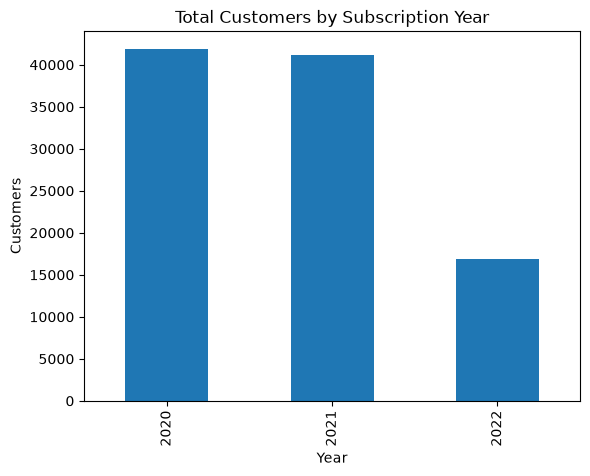

In [10]:
# data visualization
year_counts.plot(kind="bar", title="Total Customers by Subscription Year")
plt.xlabel("Year")
plt.ylabel("Customers")
plt.show()

**Total customers subscription year by year shown consistent data, from 2020 to 2021 around 40.000 customers. In 2022, the cut off month is on may (middle of the year), so safe to say that in 2020 we still have consistent subscription customers.**

#### 02. Trend Analysis
*Understand subscription trends over time.*

- Analyze monthly subscription trends
- Measure subscription growth over time
- Identify seasonal patterns or significant changes

In [11]:
# Monthly subscription trend, growth, and seasonality
monthly = df["Subscription Date"].dt.to_period("M").value_counts().sort_index()
print(monthly)

Subscription Date
2020-01    3557
2020-02    3271
2020-03    3530
2020-04    3431
2020-05    3500
2020-06    3540
2020-07    3516
2020-08    3552
2020-09    3504
2020-10    3481
2020-11    3400
2020-12    3616
2021-01    3580
2021-02    3106
2021-03    3522
2021-04    3362
2021-05    3511
2021-06    3384
2021-07    3490
2021-08    3531
2021-09    3357
2021-10    3420
2021-11    3427
2021-12    3521
2022-01    3523
2022-02    3178
2022-03    3564
2022-04    3392
2022-05    3234
Freq: M, Name: count, dtype: int64


In [12]:
print("\nMean:", monthly.mean().round(1), "Std:", monthly.std().round(1))


Mean: 3448.3 Std: 124.1


In [13]:
# Monthly breakdown per year to see spikes within each year
month_by_year = df.groupby([df["Subscription Date"].dt.year, df["Subscription Date"].dt.month]).size().unstack(0)
month_by_year.index.name = "Month"
print(month_by_year)
print("\nPeak month per year:")
print(month_by_year.idxmax())

Subscription Date    2020    2021    2022
Month                                    
1                  3557.0  3580.0  3523.0
2                  3271.0  3106.0  3178.0
3                  3530.0  3522.0  3564.0
4                  3431.0  3362.0  3392.0
5                  3500.0  3511.0  3234.0
6                  3540.0  3384.0     NaN
7                  3516.0  3490.0     NaN
8                  3552.0  3531.0     NaN
9                  3504.0  3357.0     NaN
10                 3481.0  3420.0     NaN
11                 3400.0  3427.0     NaN
12                 3616.0  3521.0     NaN

Peak month per year:
Subscription Date
2020    12
2021     1
2022     3
dtype: int32


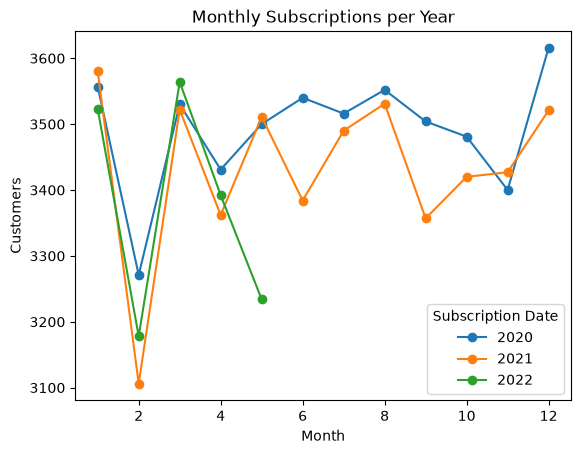

In [14]:
# data visualization
month_by_year.plot(kind="line", marker="o", title="Monthly Subscriptions per Year")
plt.xlabel("Month")
plt.ylabel("Customers")
plt.show()

**the table shown that every year we still have strong and stable subscribers**

**February is the lowest subscription customers every year, but I think this is does not mean that our sales is weakening at february, it's simply because February has fewer days, not weakening in demand. We can see that after the dip at february, at March we still have strong customer subscriptions**

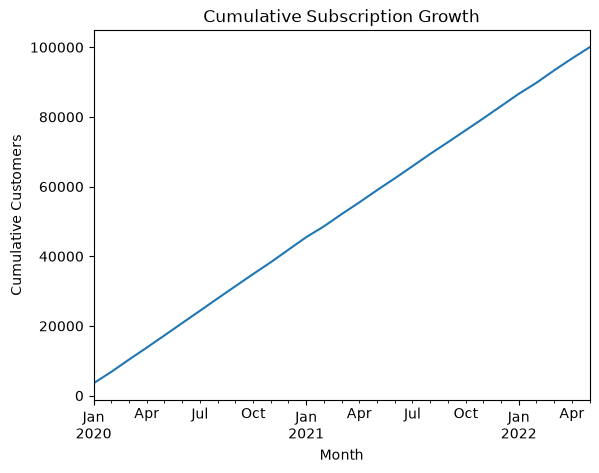

In [15]:
# data visualization
monthly.cumsum().plot(kind="line", title="Cumulative Subscription Growth")
plt.xlabel("Month")
plt.ylabel("Cumulative Customers")
plt.show()

**the table shown we still have very positive customer growth**

**from January 2020 untuk March 2022 we have around 100.000 unique customers**

#### 03. Geographical Subscription Analysis
*Understand subscription patterns across countries.*

- Analyze subscription distribution by country
- Compare subscription trends across countries

In [16]:
# Subscription distribution by country
country_counts = df["Country"].value_counts()
print(country_counts.head(10))
print("\nTotal countries:", country_counts.shape[0])
print("Min:", country_counts.min(), "Max:", country_counts.max())

Country
Congo                    835
Korea                    820
Saudi Arabia             463
Pitcairn Islands         456
Saint Martin             453
Paraguay                 445
Canada                   444
American Samoa           443
Saint Kitts and Nevis    443
Mauritania               441
Name: count, dtype: int64

Total countries: 243
Min: 359 Max: 835


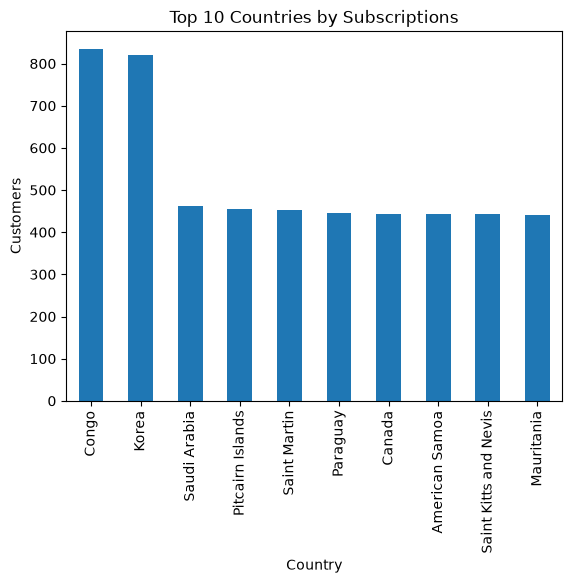

In [17]:
# data visualization
country_counts.head(10).plot(kind="bar", title="Top 10 Countries by Subscriptions")
plt.xlabel("Country")
plt.ylabel("Customers")
plt.show()

In [18]:
# Breakdown of customers and cities for the top 2 countries: Congo and Korea
top2 = country_counts.head(2).index.tolist()
for c in top2:
    sub = df[df["Country"] == c]
    print(f"{c}: {len(sub)} customers, {sub['City'].nunique()} unique cities")
    print(sub["City"].value_counts().head(10))
    print()

Congo: 835 customers, 829 unique cities
City
Bradleyfort          2
Marksview            2
Barbermouth          2
New Vicki            2
North Jean           2
East Stefanie        2
North Laurenburgh    1
Port Spencer         1
Carterchester        1
Keithville           1
Name: count, dtype: int64

Korea: 820 customers, 812 unique cities
City
Valerieview       2
South Clarence    2
New Lance         2
Elliottview       2
Fernandotown      2
Kylieberg         2
North Manuel      2
Brianaview        2
New Fred          1
South Ralph       1
Name: count, dtype: int64



**the city breakdown for 2 top county shown stable customers distribution, so no dominating city for those country**

In [19]:
# Top cities by customer count
city_counts = df["City"].value_counts()
print(city_counts.head(10))
print(f"\nCities with exactly 1 customer: {(city_counts == 1).sum()} / {city_counts.shape[0]} ({(city_counts == 1).mean():.1%})")

City
Lake Frederick     16
East Lee           15
West Alec          15
New Christopher    15
East Jeremy        15
New Wayne          14
West Bailey        14
Lake Alexander     14
North Jim          13
West Carla         13
Name: count, dtype: int64

Cities with exactly 1 customer: 27221 / 49154 (55.4%)


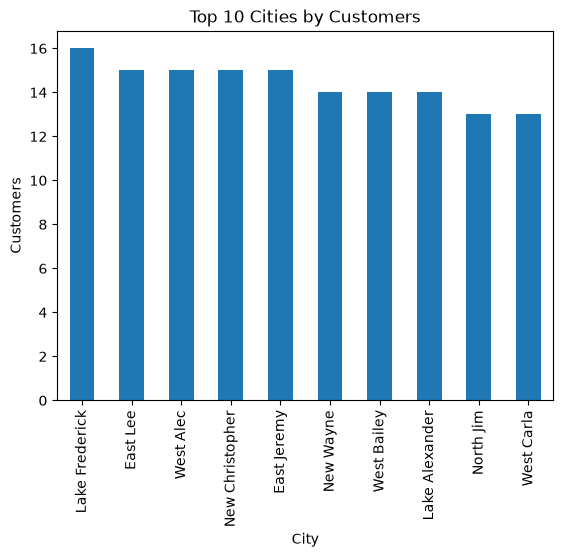

In [20]:
# data visualization
city_counts.head(10).plot(kind="bar", title="Top 10 Cities by Customers")
plt.xlabel("City")
plt.ylabel("Customers")
plt.show()

**No city dominates**: 55.4% of cities have exactly one customer, and the busiest city (Lake Frederick) has only 16 out of 100.000. same pattern seen at the country level.

#### 04. Customer Profiling based on company
*Gather customer profile based on company*


In [21]:
# Top companies by customer count
company_counts = df["Company"].value_counts()
print(company_counts.head(10))
print(f"\nCompanies with exactly 1 customer: {(company_counts == 1).sum()} / {company_counts.shape[0]} ({(company_counts == 1).mean():.1%})")

Company
Campbell Ltd        17
Wilkerson Ltd       17
Booker and Sons     16
Acosta Ltd          16
Gregory Group       15
Mccarty and Sons    15
Mckenzie PLC        15
Gomez Inc           14
Farmer Ltd          14
Garza Group         14
Name: count, dtype: int64

Companies with exactly 1 customer: 65614 / 71994 (91.1%)


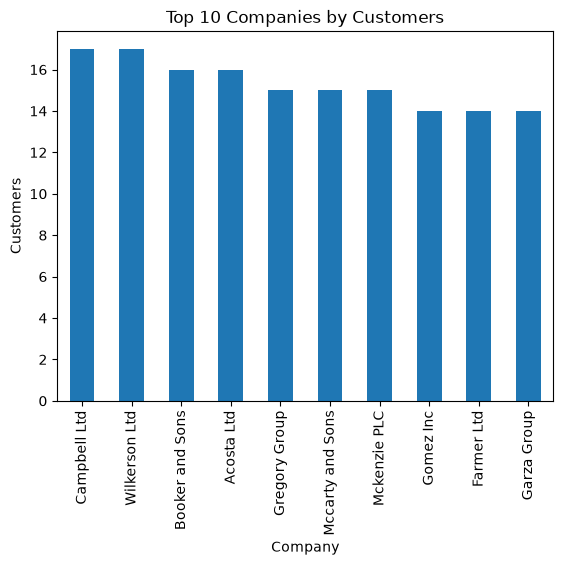

In [22]:
# data visualization
company_counts.head(10).plot(kind="bar", title="Top 10 Companies by Customers")
plt.xlabel("Company")
plt.ylabel("Customers")
plt.show()

- No company dominates: 91.1% of companies have exactly one customer, and the busiest company (Campbell Ltd / Wilkerson Ltd) has only 17 customers

- Put together with the geographical findings, every dimension we can profile (country, city, company) is close to uniformly spread, with no concentrated segment

---------------------------------------------------------

#### 05. Business Insight and To DO
*Conclution of the data exloration*

**Objective recap:** understand customer subscription patterns and identify trends that can support CRM decision making.

1. **Subscribers is flat, not growing or shrinking.** Subscriptions hold steady at around 3.500/month, through 2020-mid 2022, with February only dipping because it has fewer days. 

*To-do: CRM should not expect growth from current channels alone. To reach growth targets, new acquisition strategies are needed, such as campaigns, new channels, or partnerships.*

2. **No segment to prioritize.** Country, city, and company are all uniformly spread, with no dominant market, city.
 
*To-do: Add spending, engagement, and product usage data to support more effective customer segmentation by geography and account.*

3. **Renewal and churn can't be measured yet.** Every subscription record is a single one time event Customer Id and Email are effectively unique per customer, so there's no way to tell who renewed subscriptions.

-------------------------------------------